# Lab 1: Use Python and model APIs in Colab

To start, save a copy to Google Drive (File, then Save a copy in Drive) and pick a GPU runtime (Runtime, then Change runtime type, then T4 GPU). This lab goes with Lecture 4 and Milestone 2, and in it students send the same request to a language model and an image model many times to see how much the answers change. The outputs below are from running it on a Mac, so the answers and images in a new run will be a little different.

## 1. Setup

This installs anything that is missing and picks the GPU. Colab already has most of these packages, so it is usually quick.

In [1]:
# Install anything this notebook needs that is not already installed.
# Colab already has most of these, so this cell is usually quick.
import importlib.util, subprocess, sys

needed = {"transformers": "transformers", "accelerate": "accelerate", "diffusers": "diffusers", "pandas": "pandas", "matplotlib": "matplotlib"}  # module name: pip package name
missing = [pkg for mod, pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("Installed now:", missing or "nothing, all were already there")

Installed now: nothing, all were already there


In [2]:
import torch

# Use a GPU if there is one: "cuda" on Colab, "mps" on a recent Mac, otherwise the CPU.
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Running on", device)

Running on mps


## 2. Python used in this course

These cells show the parts of Python the labs use most: lists, dictionaries, loops, functions and pandas tables. Change something in each cell and run it again to see what happens.

In [3]:
# A list holds things in order. A dictionary maps names to values.
requests = ["Write a haiku about rain.", "Explain what a fever is to a 7-year-old."]
person = {"name": "Ana", "group": "music teachers", "uses_ai_for": "practice exercises"}

for r in requests:
    print(len(r.split()), "words:", r)

print(f"{person['name']} is one of the {person['group']}.")

5 words: Write a haiku about rain.
8 words: Explain what a fever is to a 7-year-old.
Ana is one of the music teachers.


In [4]:
# A function takes inputs and returns a result.
def shout(text, times=1):
    return (text.upper() + " ") * times

print(shout("hello"))
print(shout("hello", times=3))

HELLO 
HELLO HELLO HELLO 


In [5]:
# pandas keeps rows of results in a table (a "DataFrame") that you can sort, filter and save.
import pandas as pd

rows = [
    {"person": "P1", "task": "practice sheet", "minutes": 12},
    {"person": "P2", "task": "lesson plan", "minutes": 25},
    {"person": "P3", "task": "practice sheet", "minutes": 8},
]
table = pd.DataFrame(rows)
print(table)
print("Average minutes:", table["minutes"].mean())

  person            task  minutes
0     P1  practice sheet       12
1     P2     lesson plan       25
2     P3  practice sheet        8
Average minutes: 15.0


## 3. Load a language model

This loads Qwen2.5-1.5B-Instruct, a small open model from 2024 that is tuned to follow instructions, and downloads it the first time (about 3 GB). The tokenizer turns text into numbered tokens, and the model gives a probability for every possible next token. To try another small instruct model on Hugging Face, change `MODEL_ID`, for example to `Qwen/Qwen2.5-0.5B-Instruct` for something faster.

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16 if device != "cpu" else torch.float32,  # half precision on a GPU saves memory
).to(device)
model.eval()
print("Loaded", MODEL_ID)

Loaded Qwen/Qwen2.5-1.5B-Instruct


In [7]:
# What the tokenizer does to a sentence.
ids = tokenizer("TAs write feedback on every sketch in the class.")["input_ids"]
print(ids)
print([tokenizer.decode([i]) for i in ids])

[51, 2121, 3270, 11055, 389, 1449, 25529, 304, 279, 536, 13]
['T', 'As', ' write', ' feedback', ' on', ' every', ' sketch', ' in', ' the', ' class', '.']


## 4. Send a request

`ask` sends one request as a list of messages (a `system` message with standing instructions and a `user` message with the request) and returns the reply. `temperature` sets how random the choice of each next token is, `max_new_tokens` stops the reply after that many tokens, and `n` asks for several replies at once.

In [8]:
def ask(prompt, system="You are a helpful assistant.", temperature=0.7, max_new_tokens=150, n=1):
    messages = [
        {"role": "system", "content": system},
        {"role": "user", "content": prompt},
    ]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(device)

    settings = {"max_new_tokens": max_new_tokens, "pad_token_id": tokenizer.eos_token_id}
    if temperature == 0:
        settings["do_sample"] = False  # always take the most likely token
    else:
        # top_p=1.0 and top_k=0 turn off two other filters, so temperature is the only setting that changes
        settings.update(do_sample=True, temperature=temperature, top_p=1.0, top_k=0, num_return_sequences=n)

    with torch.no_grad():
        output = model.generate(**inputs, **settings)
    start = inputs["input_ids"].shape[1]  # the reply starts after the prompt
    replies = [tokenizer.decode(row[start:], skip_special_tokens=True).strip() for row in output]
    return replies if n > 1 else replies[0]


print(ask("Suggest a name for a bakery that only sells rye bread. Reply with the name only."))

"Rye Roots Deli"


## 5. The same request, many times

Most AI tools sample their answers, so the same request can get a different answer each time. People usually only see one of these answers. This asks ten times, keeps every answer in a table, and saves the table as lab1_runs.csv (folder icon on the left).

In [9]:
PROMPT = "I teach beginner piano. Give me one short warm-up exercise for a 9-year-old, in two sentences."

answers = ask(PROMPT, temperature=0.7, n=10)
runs = pd.DataFrame({"run": range(1, 11), "answer": answers})
runs["words"] = runs["answer"].str.split().str.len()

pd.set_option("display.max_colwidth", 200)
runs

,run,answer,words
0,1,Beginner piano students can start with simple scales: play the white keys from middle C down to A on the low end of the keyboard. This helps prepare hands and fingers for playing later on the piano.,37
1,2,One simple and effective warm-up exercise you can use with a 9-year-old is to play scales quickly in both hands side-by-side on the piano. This helps prepare their fingers and hand muscles for pla...,39
2,3,"For a 9-year-old beginning piano student, a simple and effective warm-up exercise could be to play a few scales or arpeggios while sitting comfortably at the keyboard. This helps prepare their fin...",38
3,4,Warm up your fingers and prepare to play with this simple exercise: touch the keys lightly from both hands side-to-side on middle C (C4) several times. This helps stretch your fingers and get read...,40
4,5,Beginner pianists can start with simple exercises like playing scales on both hands together or pressing soft and loud notes to help them build finger dexterity and tone control.,29
5,6,"Start with some simple finger exercises that focus on keeping the fingers relaxed and moving quickly from one note to another without tension, such as playing half-closed C's (C-G-C).",29
6,7,Beginner pianists can start with simple exercises to improve their technique and finger dexterity. One effective warm-up is to play a series of quarter notes on the right hand while left-hand fing...,73
7,8,"Beginner piano students should start with simple finger exercises to improve hand strength and coordination. One effective exercise is to ""finger through"" the keys from bottom to top while singing...",70
8,9,"A simple and effective warm-up exercise for a 9-year-old beginning pianist is to play a series of scales or arpeggios on the keyboard. Start with eight notes up and down each scale, moving quickly...",59
9,10,Beginner pianists can start with simple finger stretches and scales to enhance their technique; practice moving your fingers up and down the keys while keeping them relaxed with each other.,30


In [10]:
print("Different answers:", runs["answer"].nunique(), "of", len(runs))
print("Length in words: shortest", runs["words"].min(), ", longest", runs["words"].max())

# Save the table. In Colab, open the folder icon on the left to download the file.
runs.to_csv("lab1_runs.csv", index=False)

Different answers: 10 of 10
Length in words: shortest 29 , longest 73


Counting different strings only shows that the wording changed. To see whether the content changed, read the answers and tag each one by hand, for example by which exercise it suggests.

In [11]:
# Example: tag each answer by a word it mentions. Change the keywords to fit your own request.
def tag(answer):
    a = answer.lower()
    for keyword in ["scale", "finger", "chord", "arpeggio", "rhythm"]:
        if keyword in a:
            return keyword
    return "other"

runs["kind"] = runs["answer"].apply(tag)
runs["kind"].value_counts()

kind
scale     6
finger    4
Name: count, dtype: int64

## 6. What temperature does

For each next token, the model gives every token in its vocabulary a score, and temperature divides the scores before they become probabilities. Below 1 the most likely tokens get even more of the probability, and above 1 it spreads out to less likely tokens, as the three charts show.

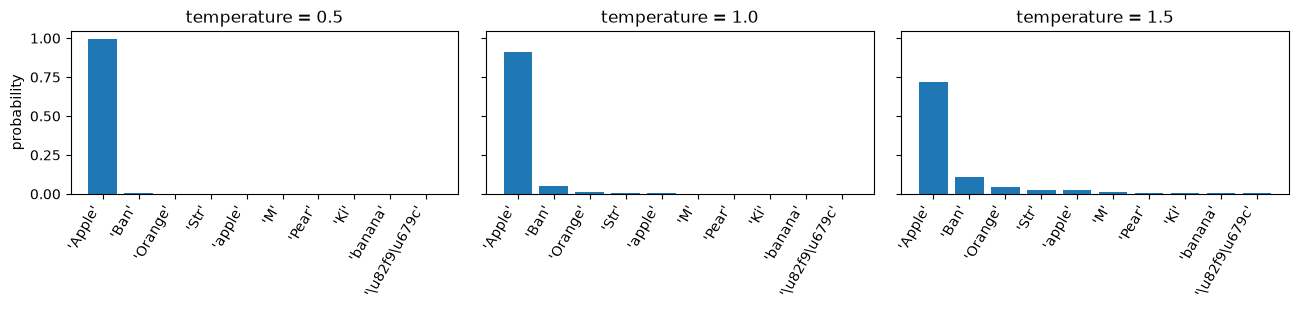

In [12]:
import matplotlib.pyplot as plt

def next_token_probs(prompt, temperature=1.0, k=10):
    messages = [{"role": "user", "content": prompt}]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(device)
    with torch.no_grad():
        scores = model(**inputs).logits[0, -1].float()  # scores for the next token
    probs = torch.softmax(scores / temperature, dim=-1)
    top = torch.topk(probs, k)
    return [tokenizer.decode([int(i)]) for i in top.indices], top.values.cpu().numpy()

prompt = "Name one fruit. Reply with one word."
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, t in zip(axes, [0.5, 1.0, 1.5]):
    tokens, p = next_token_probs(prompt, temperature=t)
    ax.bar(range(len(p)), p)
    ax.set_xticks(range(len(p)))
    ax.set_xticklabels([ascii(x) for x in tokens], rotation=60, ha="right")  # ascii() spells out characters the font may lack
    ax.set_title(f"temperature = {t}")
axes[0].set_ylabel("probability")
plt.tight_layout()
plt.show()

In [13]:
# The same request at three temperatures, 8 answers each.
rows = []
for t in [0, 0.7, 1.3]:
    if t == 0:
        replies = [ask(prompt, temperature=0, max_new_tokens=10) for _ in range(8)]
    else:
        replies = ask(prompt, temperature=t, max_new_tokens=10, n=8)
    for r in replies:
        rows.append({"temperature": t, "answer": r})
by_temp = pd.DataFrame(rows)
by_temp.groupby("temperature")["answer"].agg(different="nunique", answers=lambda s: " | ".join(sorted(set(s))))

,different,answers
temperature,,
0.0,1,Apple
0.7,1,Apple
1.3,4,Apple | Apple. | Banana | Orange


At temperature 0 every answer is the same. In the run above, 0.7 also gave "Apple" every time, while 1.3 gave four different answers, one of them with a period added. At a higher temperature, answers may stop following the instruction. Most AI products set the temperature for the user and do not show it.

## 7. Make images with an open image model

A diffusion model starts from random noise and removes it step by step, guided by the prompt (Lecture 4), and the seed picks the starting noise. This frees the language model's memory and loads SD-Turbo, a small model from 2023 that makes an image in one step (about 2.5 GB). It has no safety filter, so please take care with what it makes and what is shown to people.

In [14]:
import gc
del model
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as diffusers_logging
diffusers_logging.set_verbosity_error()  # hide loading messages
diffusers_logging.disable_progress_bar()

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    variant="fp16",
).to(device)
pipe.set_progress_bar_config(disable=True)

def make_image(prompt, seed, steps=1):
    generator = torch.Generator("cpu").manual_seed(seed)  # the seed fixes the starting noise
    # SD-Turbo was trained to work without classifier-free guidance, so guidance_scale stays at 0
    return pipe(prompt, num_inference_steps=steps, guidance_scale=0.0, generator=generator).images[0]

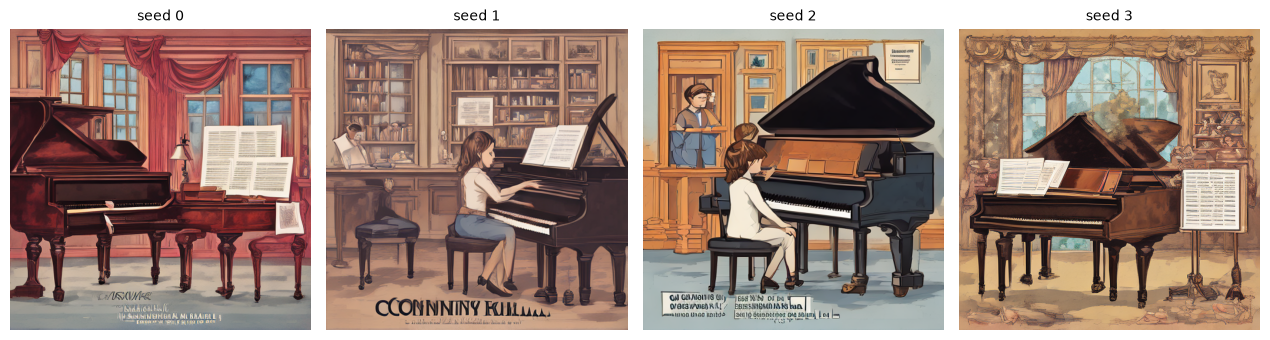

In [15]:
def show_row(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(3.2 * len(images), 3.4))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

prompt = "a poster for a community piano recital, flat illustration"
seeds = [0, 1, 2, 3]
show_row([make_image(prompt, s) for s in seeds], [f"seed {s}" for s in seeds])

Identical: True


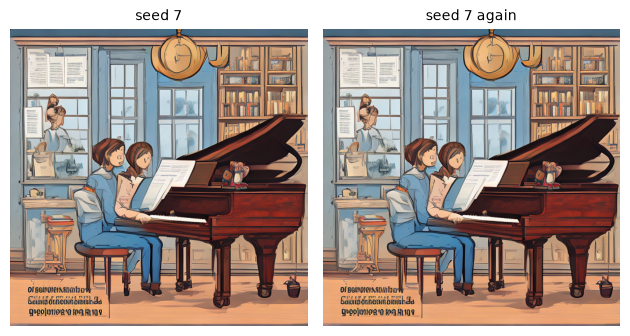

In [16]:
# Same prompt and the same seed twice: the images are identical.
import numpy as np

a = make_image(prompt, seed=7)
b = make_image(prompt, seed=7)
print("Identical:", np.array_equal(np.array(a), np.array(b)))
show_row([a, b], ["seed 7", "seed 7 again"])

On a GPU, "Identical" can sometimes print False even with the same seed, because some GPU math is not exactly repeatable, but the two images still look the same.

## 8. (Optional) Call a model through an API

Larger models run on a company's servers, and requests are sent to them through an API with an API key. For example, make a free Gemini key at aistudio.google.com and add it in Colab's Secrets panel (the key icon on the left) as `GEMINI_API_KEY`. Please never paste a key into a cell. Free tiers often let the provider keep what is sent, so do not send anything private, such as students' notes on what people from their group said. Without a key, the next cell skips the call.

In [17]:
import os, requests

def get_secret(name):
    try:
        from google.colab import userdata  # only exists on Colab
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)  # elsewhere, read it from an environment variable

# Most providers accept the same request format (the one OpenAI's API uses).
# To switch providers, change these three lines.
BASE_URL = "https://generativelanguage.googleapis.com/v1beta/openai/"
API_MODEL = "gemini-4-hydrogen"
KEY_NAME = "GEMINI_API_KEY"

def ask_api(prompt, temperature=0.7, max_tokens=2000):
    response = requests.post(
        BASE_URL + "chat/completions",
        headers={"Authorization": f"Bearer {get_secret(KEY_NAME)}"},
        json={"model": API_MODEL, "messages": [{"role": "user", "content": prompt}],
              "temperature": temperature, "max_tokens": max_tokens,
              "reasoning_effort": "low"},  # think only briefly; remove this line for a model that does not think
        timeout=60,
    )
    response.raise_for_status()  # stops with an error message if the request failed
    choice = response.json()["choices"][0]
    # If the model used up max_tokens while thinking, the reply has no text.
    return choice["message"].get("content") or f"(no text: the reply stopped because of {choice['finish_reason']})"

if get_secret(KEY_NAME):
    print(ask_api(PROMPT))
else:
    print(f"No {KEY_NAME} found, so this step is skipped. The rest of the notebook does not need it.")

No GEMINI_API_KEY found, so this step is skipped. The rest of the notebook does not need it.


The request has the same parts as before: messages, a temperature and a length limit. Newer models such as this one think before they answer, and the thinking counts toward `max_tokens`. So the limit here is 2,000 tokens instead of the 150 in `ask`, and `reasoning_effort` keeps the thinking short. With a limit of 300, this model used all of it on thinking and sent back no text. Model names change often, so if there is an error that the model was not found, look up a current one in the provider's documentation.

## Exercises

These help with Milestone 2 (Make it understandable), where students build a prototype that shows people when the AI might be wrong. Before that, it helps to know how much the AI's answers to their group's requests can change.

**Exercise 1.** Write three requests that someone in the group might really send, for example a TA asking for two sentences of feedback on a student's sketch. Ask each one 10 times at temperature 0.7, and save all 30 answers in one table and one CSV file.

In [18]:
# Exercise 1: your code here

**Exercise 2.** For one of the requests, read the 10 answers and add a column for what each answer says (for example, a fact, a decision or a recommendation), not how it is worded. How many different answers were there, and which differences would change what the person does next?

In [19]:
# Exercise 2: your code here

**Exercise 3.** Change only the system message (for example, "Answer in one sentence." or "You are a careful teaching assistant.") and repeat Exercise 2. Did the answers vary more or less? Also check whether the tool the group uses lets people see or change anything like this.

In [20]:
# Exercise 3: your code here

**Exercise 4.** Make 8 images for one request from the group with seeds 0 to 7, and pick the one to show the person. Then keep that seed and change one word in the prompt. What stayed the same, and what changed?

In [21]:
# Exercise 4: your code here